In [3]:
# =====================================================================
# CNN INVERSION — OPTIMIZED FOR GPU SPEED
# =====================================================================
import os
import time
import numpy as np
import torch
import torch.nn as nn
from torchsummary import summary
from scipy.io import loadmat

# =====================================================================
# 1. REPRODUCIBILITY + GPU SPEED SETTINGS
# =====================================================================
SEED = 123
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Using device: {device}")

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
# =====================================================================
# 2. PARAMETERS
# =====================================================================
epochs = 300
patience = 280
threshold = 1e-4

tra_num = 2600
val_num = 400
syn_num = 200

batch_size = 32
noise_level = 0.1

density = 1000
num_cell = 32
num_depth = 16

learning_rate = 3e-4
start_fm = 64

total_num = tra_num + val_num

dataFile = './data/tra&val/data{}.mat'
syn_dataFile = './data/syn/data{}.mat'
# =====================================================================
# 3. U-NET BLOCK
# =====================================================================

class double_conv(nn.Module):

    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1, padding=1):

        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size, stride, padding, bias=True),
            nn.BatchNorm2d(out_channels),
            nn.ELU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size, stride, padding, bias=True),
            nn.BatchNorm2d(out_channels),
            nn.ELU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


# =====================================================================
# 4. U-NET
# =====================================================================

class Unet(nn.Module):

    def __init__(self):

        super().__init__()

        # Encoder
        self.double_conv1 = double_conv(1, start_fm, 3, 1, 1)

        self.maxpool1 = nn.Sequential(
            nn.Conv2d(start_fm, start_fm, 2, 2, 0, bias=True),
            nn.BatchNorm2d(start_fm),
            nn.ELU(inplace=True)
        )

        self.double_conv2 = double_conv(start_fm, start_fm * 2, 3, 1, 1)

        self.maxpool2 = nn.Sequential(
            nn.Conv2d(start_fm * 2, start_fm * 2, 2, 2, 0, bias=True),
            nn.BatchNorm2d(start_fm * 2),
            nn.ELU(inplace=True)
        )

        self.double_conv3 = double_conv(start_fm * 2, start_fm * 4, 3, 1, 1)

        self.maxpool3 = nn.Sequential(
            nn.Conv2d(start_fm * 4, start_fm * 4, 2, 2, 0, bias=True),
            nn.BatchNorm2d(start_fm * 4),
            nn.ELU(inplace=True)
        )

        self.double_conv4 = double_conv(start_fm * 4, start_fm * 8, 3, 1, 1)

        self.maxpool4 = nn.Sequential(
            nn.Conv2d(start_fm * 8, start_fm * 8, 2, 2, 0, bias=True),
            nn.BatchNorm2d(start_fm * 8),
            nn.ELU(inplace=True)
        )

        self.double_conv5 = double_conv(start_fm * 8, start_fm * 16, 3, 1, 1)

        # Dropout
        self.dropout = nn.Dropout(0.20)

        # Decoder
        self.t_conv4 = nn.ConvTranspose2d(start_fm * 16, start_fm * 8, 2, 2)
        self.ex_double_conv4 = double_conv(start_fm * 16, start_fm * 8, 3, 1, 1)

        self.t_conv3 = nn.ConvTranspose2d(start_fm * 8, start_fm * 4, 2, 2)
        self.ex_double_conv3 = double_conv(start_fm * 8, start_fm * 4, 3, 1, 1)

        self.t_conv2 = nn.ConvTranspose2d(start_fm * 4, start_fm * 2, 2, 2)
        self.ex_double_conv2 = double_conv(start_fm * 4, start_fm * 2, 3, 1, 1)

        self.t_conv1 = nn.ConvTranspose2d(start_fm * 2, start_fm, 2, 2)
        self.ex_double_conv1 = double_conv(start_fm * 2, start_fm, 3, 1, 1)

        # Output
        self.ex_double_conv0 = double_conv(start_fm, 16, 3, 1, 1)

        self.final = nn.Sequential(
            nn.Conv2d(16, 16, kernel_size=1, padding=0, bias=True),
            nn.BatchNorm2d(16),
            nn.Sigmoid()
        )


    def forward(self, inputs):

        conv1 = self.double_conv1(inputs)

        maxpool1 = self.dropout(self.maxpool1(conv1))

        conv2 = self.double_conv2(maxpool1)

        maxpool2 = self.dropout(self.maxpool2(conv2))

        conv3 = self.double_conv3(maxpool2)

        maxpool3 = self.dropout(self.maxpool3(conv3))

        conv4 = self.double_conv4(maxpool3)

        maxpool4 = self.dropout(self.maxpool4(conv4))

        conv5 = self.double_conv5(maxpool4)

        t_conv4 = self.dropout(self.t_conv4(conv5))
        ex_conv4 = self.ex_double_conv4(torch.cat([conv4, t_conv4], 1))

        t_conv3 = self.dropout(self.t_conv3(ex_conv4))
        ex_conv3 = self.ex_double_conv3(torch.cat([conv3, t_conv3], 1))

        t_conv2 = self.dropout(self.t_conv2(ex_conv3))
        ex_conv2 = self.ex_double_conv2(torch.cat([conv2, t_conv2], 1))

        t_conv1 = self.dropout(self.t_conv1(ex_conv2))
        ex_conv1 = self.ex_double_conv1(torch.cat([conv1, t_conv1], 1))

        ex_conv0 = self.ex_double_conv0(ex_conv1)

        return self.final(ex_conv0)


# =====================================================================
# 5. DICE LOSS
# =====================================================================

def dice(pred, target):

    smooth = 1.0
    num = pred.size(0)

    pred = pred.reshape(num, -1)
    target = target.reshape(num, -1)

    intersection = pred * target

    dice_score = (2.0 * intersection.sum(1) + smooth) / (
        (pred * pred).sum(1) +
        (target * target).sum(1) +
        smooth
    )

    return dice_score.mean()


def my_loss(pred, target):
    return 1.0 - dice(pred, target)


# =====================================================================
# 6. LOAD DATA DIRECTLY INTO NUMPY ARRAYS
# =====================================================================

tra_x = np.empty((tra_num, 1, num_cell, num_cell), dtype=np.float32)
tra_y = np.empty((tra_num, num_depth, num_cell, num_cell), dtype=np.float32)

val_x = np.empty((val_num, 1, num_cell, num_cell), dtype=np.float32)
val_y = np.empty((val_num, num_depth, num_cell, num_cell), dtype=np.float32)

syn_x = np.empty((syn_num, 1, num_cell, num_cell), dtype=np.float32)
syn_y = np.empty((syn_num, num_depth, num_cell, num_cell), dtype=np.float32)


# =====================================================================
# 7. LOAD TRAINING DATA
# =====================================================================

for i in range(tra_num):

    data = loadmat(dataFile.format(i))

    tra_x[i, 0] = np.nan_to_num(
        data['d'].flatten()
    ).reshape(num_cell, num_cell)

    tra_y[i] = (
        np.nan_to_num(data['m'].flatten()) / density
    ).reshape(num_depth, num_cell, num_cell)


# =====================================================================
# 8. LOAD VALIDATION DATA
# =====================================================================

for i in range(val_num):

    data = loadmat(dataFile.format(tra_num + i))

    val_x[i, 0] = np.nan_to_num(
        data['d'].flatten()
    ).reshape(num_cell, num_cell)

    val_y[i] = (
        np.nan_to_num(data['m'].flatten()) / density
    ).reshape(num_depth, num_cell, num_cell)


# =====================================================================
# 9. LOAD SYNTHETIC DATA
# =====================================================================

for i in range(syn_num):

    data = loadmat(syn_dataFile.format(i))

    syn_x[i, 0] = np.nan_to_num(
        data['d'].flatten()
    ).reshape(num_cell, num_cell)

    syn_y[i] = (
        np.nan_to_num(data['m'].flatten()) / density
    ).reshape(num_depth, num_cell, num_cell)


print("Training and validation data loaded successfully!")


# =====================================================================
# 10. ADD 10% GAUSSIAN NOISE
# =====================================================================

def add_gaussian_noise(data, noise_level=0.1, seed=123):
    rng = np.random.default_rng(seed)
    noisy = data.copy()

    for i in range(len(data)):
        sigma = noise_level * np.std(data[i])
        noise = rng.normal(0.0, sigma, size=data[i].shape).astype(np.float32)
        noisy[i] = data[i] + noise

    return noisy

tra_x = add_gaussian_noise(tra_x, noise_level=0.1, seed=123)
val_x = add_gaussian_noise(val_x, noise_level=0.1, seed=123)
syn_x = add_gaussian_noise(syn_x, noise_level=0.1, seed=123)

# =====================================================================
# 11. CONVERT DATA TO PYTORCH TENSORS ONCE
# =====================================================================

tra_x = torch.from_numpy(tra_x)
tra_y = torch.from_numpy(tra_y)

val_x = torch.from_numpy(val_x)
val_y = torch.from_numpy(val_y)

syn_x = torch.from_numpy(syn_x)
syn_y = torch.from_numpy(syn_y)


# =====================================================================
# 12. MOVE DATA TO GPU
# =====================================================================

if torch.cuda.is_available():

    tra_x = tra_x.to(device)
    tra_y = tra_y.to(device)

    val_x = val_x.to(device)
    val_y = val_y.to(device)

    syn_x = syn_x.to(device)
    syn_y = syn_y.to(device)

    print("All datasets transferred to GPU.")


# =====================================================================
# 13. DATASET
# =====================================================================

class TensorDataset(torch.utils.data.Dataset):

    def __init__(self, images, masks):
        self.images = images
        self.masks = masks

    def __len__(self):
        return self.images.shape[0]

    def __getitem__(self, idx):
        return self.images[idx], self.masks[idx]


tra = TensorDataset(tra_x, tra_y)
val = TensorDataset(val_x, val_y)
syn = TensorDataset(syn_x, syn_y)


# =====================================================================
# 14. DATA LOADERS
# =====================================================================

tra_loader = torch.utils.data.DataLoader(
    tra,
    batch_size=batch_size,
    shuffle=True
)

val_loader = torch.utils.data.DataLoader(
    val,
    batch_size=batch_size,
    shuffle=False
)

syn_loader = torch.utils.data.DataLoader(
    syn,
    batch_size=batch_size,
    shuffle=False
)


# =====================================================================
# 15. MODEL
# =====================================================================

model = Unet().to(device)

print("\nModel summary:")
summary(model, input_size=(1, 32, 32), device=str(device))


# =====================================================================
# 16. OPTIMIZER
# =====================================================================

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate
)


# =====================================================================
# 17. LOSS HISTORY
# =====================================================================

mean_tra_losses = []
mean_val_losses = []
mean_syn_losses = []


# =====================================================================
# 18. BEST MODEL
# =====================================================================

model_File = './parameters1.pth'

best_val_loss = float('inf')
best_epoch = 0
no_improve = 0


# =====================================================================
# 19. TRAINING
# =====================================================================

start = time.time()

for epoch in range(1, epochs + 1):

    # ---------------------------------------------------------------
    # TRAINING
    # ---------------------------------------------------------------

    model.train()

    tra_loss_sum = 0.0
    tra_batches = 0

    for images, masks in tra_loader:

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)

        loss = my_loss(outputs, masks)

        loss.backward()
        optimizer.step()

        tra_loss_sum += loss.item()
        tra_batches += 1


    mean_tra_loss = tra_loss_sum / tra_batches


    # ---------------------------------------------------------------
    # VALIDATION
    # ---------------------------------------------------------------

    model.eval()

    val_loss_sum = 0.0
    val_batches = 0

    with torch.inference_mode():

        for images, masks in val_loader:

            outputs = model(images)

            loss = my_loss(outputs, masks)

            val_loss_sum += loss.item()
            val_batches += 1


    mean_val_loss = val_loss_sum / val_batches


    # ---------------------------------------------------------------
    # SYNTHETIC VALIDATION
    # ---------------------------------------------------------------

    syn_loss_sum = 0.0
    syn_batches = 0

    with torch.inference_mode():

        for images, masks in syn_loader:

            outputs = model(images)

            loss = my_loss(outputs, masks)

            syn_loss_sum += loss.item()
            syn_batches += 1


    mean_syn_loss = syn_loss_sum / syn_batches


    # ---------------------------------------------------------------
    # SAVE LOSSES
    # ---------------------------------------------------------------

    mean_tra_losses.append(mean_tra_loss)
    mean_val_losses.append(mean_val_loss)
    mean_syn_losses.append(mean_syn_loss)


    # ---------------------------------------------------------------
    # PRINT
    # ---------------------------------------------------------------

    print(
        f"Epoch: {epoch:03d} | "
        f"Tra: {mean_tra_loss:.4f} | "
        f"Val: {mean_val_loss:.4f} | "
        f"Syn: {mean_syn_loss:.4f}"
    )


    # ---------------------------------------------------------------
    # SAVE BEST MODEL
    # ---------------------------------------------------------------

    if mean_val_loss < best_val_loss - threshold:

        best_val_loss = mean_val_loss
        best_epoch = epoch
        no_improve = 0

        torch.save(model.state_dict(), model_File)

        print(
            f"Best model saved at epoch {epoch} "
            f"(val_loss={best_val_loss:.6f})"
        )

    else:

        no_improve += 1


    # ---------------------------------------------------------------
    # EARLY STOPPING
    # ---------------------------------------------------------------

    if no_improve >= patience:

        print(
            f"Early stopping at epoch {epoch}."
        )

        break


# =====================================================================
# 20. TRAINING TIME
# =====================================================================

run_time = time.time() - start

print("\n========================================")
print("TRAINING COMPLETED")
print("========================================")
print(f"Best epoch      : {best_epoch}")
print(f"Best val loss   : {best_val_loss:.6f}")
print(f"Epochs executed : {epoch}")
print(f"Training time   : {run_time:.2f} s")
print("========================================")


# =====================================================================
# 21. LOAD BEST MODEL
# =====================================================================

model.load_state_dict(
    torch.load(
        model_File,
        map_location=device,
        weights_only=True
    )
)

model.to(device)
model.eval()


# =====================================================================
# 22. FINAL VALIDATION PREDICTION
# =====================================================================

val_predict = []
val_truth = []
val_truth_d = []

with torch.inference_mode():

    for images, masks in val_loader:

        outputs = model(images)

        val_predict.append(
            outputs.detach().cpu().numpy()
        )

        val_truth.append(
            masks.detach().cpu().numpy()
        )

        val_truth_d.append(
            images.detach().cpu().numpy()
        )
val_predict = np.concatenate(val_predict, axis=0)
val_truth = np.concatenate(val_truth, axis=0)
val_truth_d = np.concatenate(val_truth_d, axis=0)
# =====================================================================
# 23. FINAL SYNTHETIC PREDICTION
# =====================================================================
syn_predict = []
syn_truth = []
syn_truth_d = []

with torch.inference_mode():

    for images, masks in syn_loader:

        outputs = model(images)

        syn_predict.append(
            outputs.detach().cpu().numpy()
        )

        syn_truth.append(
            masks.detach().cpu().numpy()
        )

        syn_truth_d.append(
            images.detach().cpu().numpy()
        )
syn_predict = np.concatenate(syn_predict, axis=0)
syn_truth = np.concatenate(syn_truth, axis=0)
syn_truth_d = np.concatenate(syn_truth_d, axis=0)
# =====================================================================
# 24. FINAL SHAPES
# =====================================================================
val_predict = val_predict.reshape(val_num, -1)
val_truth = val_truth.reshape(val_num, -1)
val_truth_d = val_truth_d.reshape(val_num, -1)

syn_predict = syn_predict.reshape(syn_num, -1)
syn_truth = syn_truth.reshape(syn_num, -1)
syn_truth_d = syn_truth_d.reshape(syn_num, -1)

# =====================================================================
# 25. FINAL INFORMATION
# =====================================================================
print("\n================================================")
print("INVERSION COMPLETED")
print("================================================")
print(f"Best validation loss : {best_val_loss:.6f}")
print(f"Best epoch           : {best_epoch}")
print(f"Validation truth     : {val_truth.shape}")
print(f"Validation prediction: {val_predict.shape}")
print(f"Synthetic truth      : {syn_truth.shape}")
print(f"Synthetic prediction : {syn_predict.shape}")
print("================================================")



# =====================================================================
# 26. SAVE COMPLETE INVERSION RESULTS
# =====================================================================
results_file = "./CNN_inversion_results.npz"

np.savez_compressed(
    results_file,

    # Final validation results
    val_predict=val_predict,
    val_truth=val_truth,
    val_truth_d=val_truth_d,

    # Final synthetic results
    syn_predict=syn_predict,
    syn_truth=syn_truth,
    syn_truth_d=syn_truth_d,

    # Convergence histories
    mean_tra_losses=np.asarray(mean_tra_losses),
    mean_val_losses=np.asarray(mean_val_losses),
    mean_syn_losses=np.asarray(mean_syn_losses),

    # Training information
    best_epoch=best_epoch,
    best_val_loss=best_val_loss,
    run_time=run_time,

    # Model/data parameters
    density=density,
    num_cell=num_cell,
    num_depth=num_depth,
    noise_level=noise_level,
    tra_num=tra_num,
    val_num=val_num,
    syn_num=syn_num
)
print("\n==============================================")
print("COMPLETE INVERSION RESULTS SAVED")
print("==============================================")
print(f"Results file : {results_file}")
print(f"Best epoch   : {best_epoch}")
print(f"Best val loss: {best_val_loss:.6f}")
print(f"File contains validation + synthetic results")
print(f"File contains all convergence histories")
print("==============================================")

Using device: cuda
GPU: NVIDIA GeForce RTX 3050
Training and validation data loaded successfully!
All datasets transferred to GPU.

Model summary:
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 32, 32]             640
       BatchNorm2d-2           [-1, 64, 32, 32]             128
               ELU-3           [-1, 64, 32, 32]               0
            Conv2d-4           [-1, 64, 32, 32]          36,928
       BatchNorm2d-5           [-1, 64, 32, 32]             128
               ELU-6           [-1, 64, 32, 32]               0
       double_conv-7           [-1, 64, 32, 32]               0
            Conv2d-8           [-1, 64, 16, 16]          16,448
       BatchNorm2d-9           [-1, 64, 16, 16]             128
              ELU-10           [-1, 64, 16, 16]               0
          Dropout-11           [-1, 64, 16, 16]               0
           Conv2d-12

Saved CNN inversion results loaded successfully.
Synthetic prediction shape : (200, 16384)
Synthetic truth shape      : (200, 16384)
Synthetic input shape      : (200, 1024)
Best epoch                 : 145
Best validation loss       : 0.3660103862102215
Tyy matrix: torch.Size([16384, 1024])

  Calculating condition number of Tyy...
Condition number of Tyy = 7.300126e+02
  Interpretation            : Moderately ill-conditioned
  Observations : 1024
obs_tyy =
 [[ 1.8628279  -2.6214595   1.4673978  ...  1.2374747   1.5060639
   0.21344234]
 [ 0.27427387  1.3790078   0.99920213 ... -0.03314668  1.3691763
   0.7730019 ]
 [ 0.05698699  1.8370625  -0.83359283 ...  0.14350475 -1.1305103
   0.9880399 ]
 ...
 [ 1.8831977   0.56490695  2.4972339  ...  2.3551674  -1.6005042
  -1.908936  ]
 [ 1.567355    1.2267611   1.3291111  ...  2.1741073   1.0538384
   2.4790933 ]
 [ 1.7759364   3.362029    1.611089   ...  2.364461    0.4575413
   3.3714356 ]]

pre_tyy =
 [[-3.98935155 -4.3634258  -4.13033074 

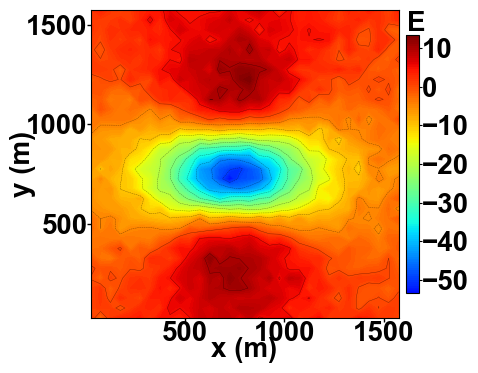

Saved: Fig01_Observed_tyy.png


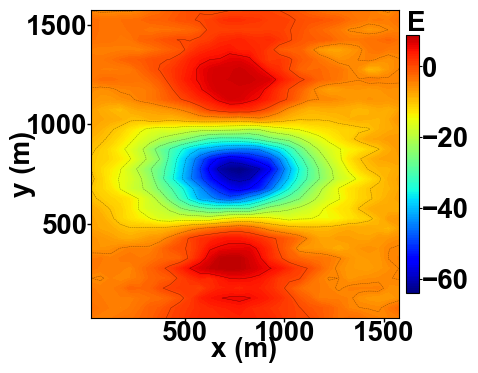

Saved: Fig02_Predicted_tyy.png


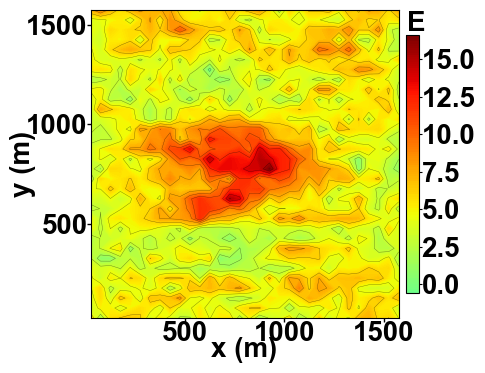

Saved: Fig03_Residual_tyy.png


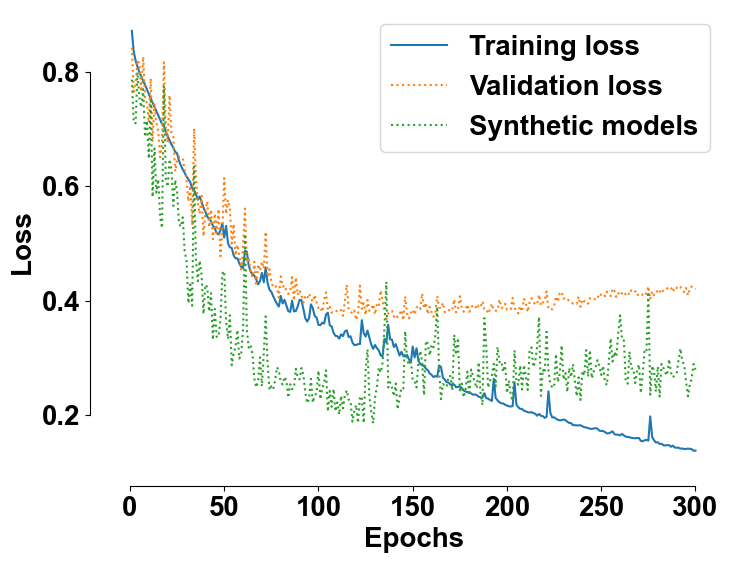

Saved: Fig04_Convergence.png
Convergence data saved to:
C:\Users\Rahul Maurya\OneDrive\Desktop\Rahul_MTP\CNN_Method\Sigle prism cnn\Convergence_Curve_Combined_all_Components\tyy_Conver_Curve_Data.xlsx
True density range     : 0.0 1000.0 kg/m³
Predicted density range: 1.3036838 999.9989 kg/m³
True model shape       : (16, 32, 32)
Predicted model shape  : (16, 32, 32)


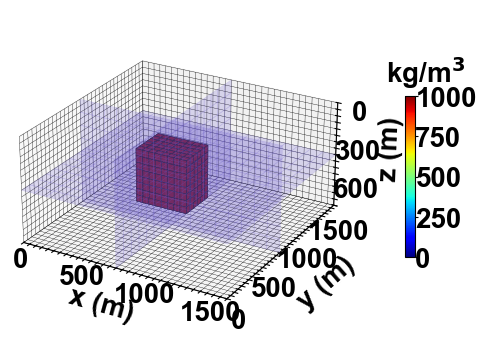

Saved: Fig05_True_3D_Density_Model.png


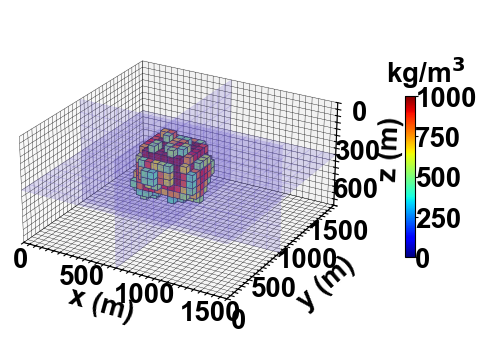

Saved: Fig06_Predicted_3D_Density_Model.png


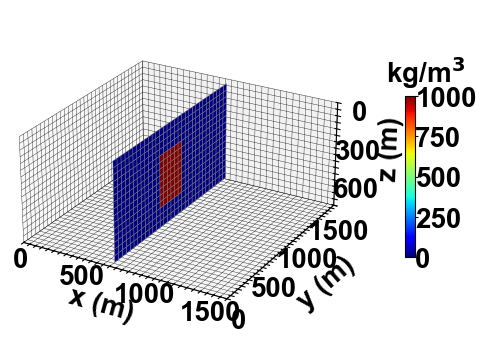

Saved: CNN_Fig07_True_YZ_x750.png


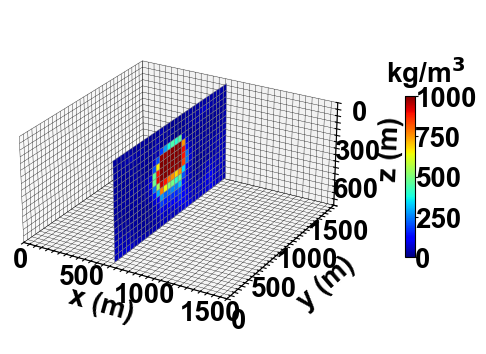

Saved: CNN_Fig08_Predicted_YZ_x750.png


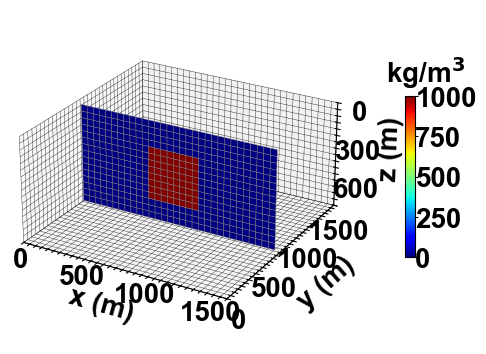

Saved: CNN_Fig09_True_XZ_y750.png


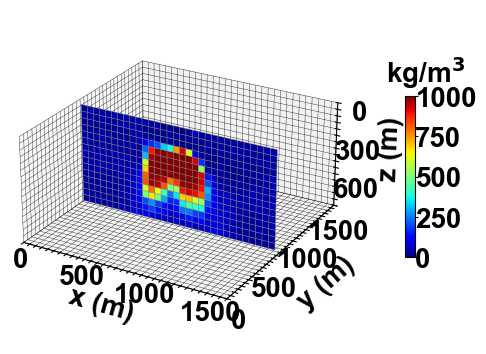

Saved: CNN_Fig10_Predicted_XZ_y750.png


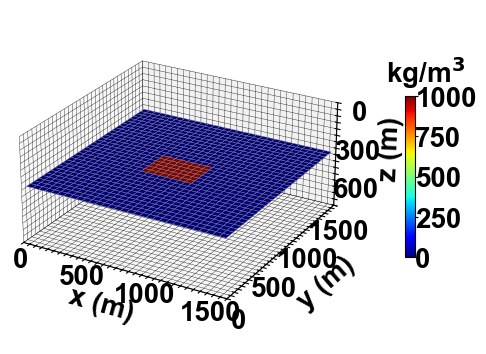

Saved: CNN_Fig11_True_XY_z400.png


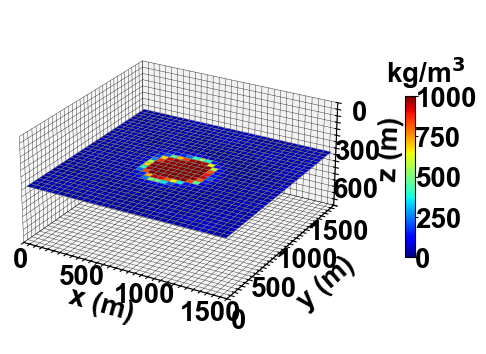

Saved: CNN_Fig12_Predicted_XY_z400.png

ALL 12 CNN PUBLICATION FIGURES SAVED SUCCESSFULLY
X/Y cell size: 50 m
X/Y tick spacing: 200 m
Z cell size: 50 m
Z tick spacing: 100 m
Density range: 0–1000 kg/m³
PNG resolution: 600 DPI
No individual figure titles


In [7]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from PIL import Image, ImageChops
from matplotlib.ticker import ScalarFormatter, MaxNLocator
from scipy.io import loadmat
import torch
# =====================================================================
# LOAD SAVED CNN INVERSION RESULTS
# =====================================================================
results_file = "./CNN_inversion_results.npz"
results = np.load(results_file)

# Final validation results
val_predict = results["val_predict"]
val_truth = results["val_truth"]
val_truth_d = results["val_truth_d"]

# Final synthetic results
syn_predict = results["syn_predict"]
syn_truth = results["syn_truth"]
syn_truth_d = results["syn_truth_d"]

# Convergence histories
mean_tra_losses = results["mean_tra_losses"]
mean_val_losses = results["mean_val_losses"]
mean_syn_losses = results["mean_syn_losses"]

# Training information
best_epoch = int(results["best_epoch"])
best_val_loss = float(results["best_val_loss"])
run_time = float(results["run_time"])

# Model/data parameters
density = float(results["density"])
num_cell = int(results["num_cell"])
num_depth = int(results["num_depth"])
noise_level = float(results["noise_level"])

print("Saved CNN inversion results loaded successfully.")
print("Synthetic prediction shape :", syn_predict.shape)
print("Synthetic truth shape      :", syn_truth.shape)
print("Synthetic input shape      :", syn_truth_d.shape)
print("Best epoch                 :", best_epoch)
print("Best validation loss       :", best_val_loss)


# =====================================================================
# CELL 2 — PLOT AND SAVE 12 FIGURES SEPARATELY
# Pure and Applied Geophysics — Publication Quality
# NO TITLES ON INDIVIDUAL FIGURES
# =====================================================================

# ── Global publication settings ──────────────────────────────────────
BG=AX="white"; TC="black"; DPI=600
mpl.rcParams.update({
    "font.family":"Arial","font.size":20,
    "axes.labelsize":20,"axes.titlesize":20,"xtick.labelsize":20,"ytick.labelsize":20,
    "legend.fontsize":20,"figure.facecolor":"white",
    "axes.facecolor":"white","savefig.dpi":600,
    "savefig.facecolor":"white","axes.edgecolor":"black",
    "axes.linewidth":.8,"xtick.color":"black","ytick.color":"black",
    "text.color":"black","axes.labelcolor":"black",
    "ps.fonttype":42,"font.weight":"bold","axes.labelweight":"bold",
    "axes.titleweight":"bold"
})
# =====================================================================
# AXIS STYLE
# =====================================================================
def _style(ax,xl="",yl=""):
    ax.set_facecolor(AX)
    ax.tick_params(axis="both",colors=TC,direction="out",width=1.0,length=3.0,pad=-1.0)
    ax.set_xlabel(xl,color=TC,labelpad=-7.0); ax.set_ylabel(yl,color=TC,labelpad=-7.0)
    for sp in ax.spines.values():
        sp.set_edgecolor(TC); sp.set_linewidth(.8)
# =====================================================================
# PUBLICATION COLORBAR
# =====================================================================
def _publication_colorbar(cf,ax,fig,title,scientific=False):
    cb=fig.colorbar(cf,ax=ax,shrink=0.84,pad=0.02,aspect=21)
    cb.ax.set_title(title,color=TC,y=0.98,x=0.8)
    cb.locator=MaxNLocator(nbins=7,steps=[1,2,2.5,5,10])  # Clean tick spacing
    cb.update_ticks()
    cb.ax.tick_params(colors=TC,direction="out",width=.8,length=2,pad=0.0)
    cb.outline.set_edgecolor(TC); cb.outline.set_linewidth(.8)
    fmt=ScalarFormatter(useMathText=False); fmt.set_scientific(scientific); fmt.set_useOffset(False)
    cb.formatter=fmt; cb.update_ticks()
    return cb

def save_fig(fig,filename,tight=True):
    kw={"dpi":600,"facecolor":BG,"pad_inches":0}
    if tight:kw["bbox_inches"]="tight"
    fig.savefig(filename,**kw)
    plt.show()
    plt.close(fig)
    crop_white_margin(filename,padding=0)
    print("Saved:",filename)

def crop_white_margin(filename,padding=0):
    img=Image.open(filename).convert("RGB")
    bbox=ImageChops.difference(img,Image.new("RGB",img.size,"white")).getbbox()
    if bbox:
        x0,y0,x1,y1=bbox
        img.crop((max(0,x0-padding),max(0,y0-padding),
                  min(img.width,x1+padding),min(img.height,y1+padding))
                ).save(filename,dpi=(DPI,DPI))
        
# =====================================================================
# LOAD TENSOR KERNEL MATRIX
# =====================================================================
Tyy=loadmat("Tyy_matrix.mat")["Tyy"]; Tyy=np.nan_to_num(Tyy)
Tyy_tensor=torch.tensor(Tyy,dtype=torch.float32).T
print("Tyy matrix:",Tyy_tensor.shape)
# =============================================================================
# CONDITION NUMBER OF THE RAW TENSOR KERNEL
# =============================================================================
print("\n  Calculating condition number of Tyy...")
condition_number_Tyy = np.linalg.cond(Tyy)
print(f"Condition number of Tyy = {condition_number_Tyy:.6e}")

if condition_number_Tyy < 1e2:
    print("  Interpretation            : Well conditioned")
elif condition_number_Tyy < 1e4:
    print("  Interpretation            : Moderately ill-conditioned")
elif condition_number_Tyy < 1e6:
    print("  Interpretation            : Strongly ill-conditioned")
elif condition_number_Tyy < 1e10:
    print("  Interpretation            : Severely ill-conditioned")
else:
    print("  Interpretation            : Extremely ill-conditioned")
print("=" * 65)
# =====================================================================
# SELECT ONE CNN SYNTHETIC MODEL
# =====================================================================
index=58
m1=syn_truth[index]; m2=syn_predict[index]; obs_tyy=syn_truth_d[index]
tru_model=m1.reshape(16,num_cell,num_cell)
pre_model=m2.reshape(16,num_cell,num_cell)
# =====================================================================
# CALCULATE PREDICTED Tyy
# =====================================================================
density_max=1000.0   # kg/m³
pre_m=density_max*np.reshape(m2,(16384,1))
pre_tyy=np.reshape(Tyy@pre_m,(32,32))
obs_tyy=np.reshape(obs_tyy,(32,32))
# =====================================================================
# OBSERVATION GRID: 32×32 @ 50 m
# =====================================================================
sp=50.0
x1d=np.arange(sp/2,1600,sp); y1d=np.arange(sp/2,1600,sp)
Xo,Yo=np.meshgrid(x1d,y1d)
obs_x=Xo.ravel(); obs_y=Yo.ravel(); obs_z=np.zeros(len(obs_x))
N_obs=len(obs_x)
print(f"  Observations : {N_obs}")
# =====================================================================
# PRISM GRID: 32×32×16
# =====================================================================
nx,ny,nz=32,32,16
dx,dy,dz=50,50,50
xe=np.linspace(0,1600,nx+1); ye=np.linspace(0,1600,ny+1); ze=np.linspace(0,800,nz+1)

iz_g,iy_g,ix_g=np.meshgrid(
    np.arange(nz),np.arange(ny),np.arange(nx),indexing="ij"
)
ix_g=ix_g.ravel(); iy_g=iy_g.ravel(); iz_g=iz_g.ravel()
px1=xe[ix_g]; px2=xe[ix_g+1]
py1=ye[iy_g]; py2=ye[iy_g+1]
pz1=ze[iz_g]; pz2=ze[iz_g+1]; pz_c=.5*(pz1+pz2)
# =====================================================================
# OBSERVATION GRID
# =====================================================================
ng=int(np.sqrt(N_obs))
X=obs_x.reshape(ng,ng); Y=obs_y.reshape(ng,ng)
Zobs=obs_tyy.reshape(ng,ng); Zpred=pre_tyy.reshape(ng,ng); Zres=Zobs-Zpred
vmin=min(Zobs.min(),Zpred.min()); vmax=max(Zobs.max(),Zpred.max())
rmax=np.max(np.abs(Zres))
# ============================================================
# Tensor and residual statistics
# ============================================================
# Observed and predicted tyy
print("obs_tyy =\n", obs_tyy)
print("\npre_tyy =\n", pre_tyy)
# Residual Tensor : observed - predicted
print("\nZres =\n", Zres)

# Maximum, Minimum & Mean values of observed tyy data
print("\nobs_tyy maximum =", np.max(obs_tyy))
print("obs_tyy minimum =", np.min(obs_tyy))
print("obs_tyy mean =", np.mean(obs_tyy))

# Maximum, Minimum & Mean values of predicted tyy data 
print("\npre_tyy maximum =", np.max(pre_tyy))
print("pre_tyy minimum =", np.min(pre_tyy))
print("pre_tyy mean =", np.mean(pre_tyy))

# Residual statistics
print("\nZres maximum =", np.max(Zres))
print("Zres minimum =", np.min(Zres))
print("Zres mean =", np.mean(Zres))

# RMS residual
rms = np.sqrt(np.mean(Zres**2))
print("\nRMS between observed and predicted =", rms)
# =====================================================================
# FIGURES 1–3 — 2-D tyy
# =====================================================================
def plot_tyy(data,filename,label,lo,hi):
    fig,ax=plt.subplots(figsize=(5,4)); fig.patch.set_facecolor(BG)
    cf=ax.contourf(X,Y,data,levels=150,cmap="jet",vmin=lo,vmax=hi)
    ax.contour(X,Y,data,levels=15,colors="k",linewidths=.3,alpha=.5)
    _style(ax,"x (m)","y (m)"); ax.set_aspect("equal")
    _publication_colorbar(cf,ax,fig,"E")
    save_fig(fig,filename)
    
plot_tyy(Zobs,"Fig01_Observed_tyy.png","tyy (E)",vmin,vmax)
plot_tyy(Zpred,"Fig02_Predicted_tyy.png","tyy (E)",vmin,vmax)
plot_tyy(Zres,"Fig03_Residual_tyy.png","tyy residual (E)",-rmax,rmax)
# =====================================================================
# FIGURE 4 — CONVERGENCE CURVE
# =====================================================================
epochs=np.arange(1,len(mean_tra_losses)+1)
fig,ax=plt.subplots(figsize=(8,6))
ax.plot(epochs,mean_tra_losses,label="Training loss")
ax.plot(epochs,mean_val_losses,linestyle=":",label="Validation loss")
ax.plot(epochs,mean_syn_losses,linestyle=":",label="Synthetic models")
sns.despine(offset=10,trim=True)
ax.set_xlabel("Epochs"); ax.set_ylabel("Loss"); ax.legend(loc="best")
save_fig(fig,"Fig04_Convergence.png")
# =====================================================================
# SAVE CONVERGENCE DATA
# =====================================================================
df=pd.DataFrame({
    "Epoch":epochs,"Training Loss":mean_tra_losses,
    "Validation Loss":mean_val_losses,"Synthetic Loss":mean_syn_losses
})
excel_file=r"C:\Users\Rahul Maurya\OneDrive\Desktop\Rahul_MTP\CNN_Method\Sigle prism cnn\Convergence_Curve_Combined_all_Components\tyy_Conver_Curve_Data.xlsx"
df.to_excel(excel_file,index=False)
print(f"Convergence data saved to:\n{excel_file}")
# =====================================================================
# TRUE PRISM BOUNDS AND 3-D SETTINGS
# =====================================================================
px_lo,px_hi=550.0,950.0; py_lo,py_hi=600.0,900.0; pz_lo,pz_hi=200.0,600.0
clim=(0,1000)
cmap_3d=plt.cm.jet
norm_3d=mpl.colors.Normalize(vmin=0,vmax=density_max)
X3,Y3,Z3=np.meshgrid(xe,ye,ze,indexing="ij")
# =====================================================================
# TRANSPARENT DENSITY-BOUNDARY PLANES
# =====================================================================
def add_density_boundaries(ax,xe,ye,ze,alpha=.20):
    Y,Z=np.meshgrid(ye,ze); X=np.full_like(Y,750.0)
    ax.plot_surface(X,Y,Z,color="slateblue",alpha=alpha,edgecolor="slateblue",
                    linewidth=.35,rstride=2,cstride=2,shade=False)
    X,Z=np.meshgrid(xe,ze); Y=np.full_like(X,750.0)
    ax.plot_surface(X,Y,Z,color="slateblue",alpha=alpha,edgecolor="slateblue",
                    linewidth=.35,rstride=2,cstride=2,shade=False)
    X,Y=np.meshgrid(xe,ye); Z=np.full_like(X,400.0)
    ax.plot_surface(X,Y,Z,color="slateblue",alpha=alpha,edgecolor="slateblue",
                    linewidth=.35,rstride=2,cstride=2,shade=False)
# =====================================================================
# COMMON 3-D AXIS SETTINGS
# =====================================================================
def setup_3d(ax):
    ax.set_xlim(0,1600); ax.set_ylim(0,1600); ax.set_zlim(800,0)
    xg=np.arange(0,1601,50); yg=np.arange(0,1601,50); zg=np.arange(0,801,50)
    ax.set_xticks(xg); ax.set_yticks(yg); ax.set_zticks(zg)
    ax.set_xticklabels([str(v) if v%500==0 else "" for v in xg])
    ax.set_yticklabels([str(v) if v%500==0 else "" for v in yg])
    ax.set_zticklabels([str(v) if v%300==0 else "" for v in zg])
    
    ax.set_xlabel("x (m)",color=TC,labelpad=0.0); ax.set_ylabel("y (m)",color=TC,labelpad=5)
    ax.set_zlabel("z (m)",color=TC,labelpad=2.0)
    
    ax.tick_params(axis="x",colors=TC,direction="out",
                   width=.7,length=3,pad=-5.0)
    ax.tick_params(axis="y",colors=TC,direction="out",
                   width=.7,length=3,pad=-1.0)
    ax.tick_params(axis="z",colors=TC,direction="out",
                   width=.7,length=3,pad=1.0) 
    ax.grid(True)
    for a in [ax.xaxis,ax.yaxis,ax.zaxis]:
        a._axinfo["grid"]["color"]="black"
        a._axinfo["grid"]["linewidth"]=.25
        a._axinfo["grid"]["linestyle"]="-"
    ax.set_facecolor(AX); ax.set_box_aspect((1600,1600,800))
    ax.view_init(elev=25,azim=-60)
# =====================================================================
# 3-D DENSITY COLORBAR
# =====================================================================
def density_3d_colorbar(fig,ax):
    sm=mpl.cm.ScalarMappable(cmap=cmap_3d,norm=norm_3d); sm.set_array([])
    cb=fig.colorbar(sm,ax=ax,shrink=0.42,pad=0.13,aspect=16)
    cb.ax.set_title(r"kg/m$^3$",color=TC,y=1.03,x=2.0)
    cb.set_ticks(np.arange(0,1001,250))
    cb.ax.tick_params(colors=TC,direction="out",width=.8,length=2,pad=-2.0)
    cb.outline.set_edgecolor(TC); cb.outline.set_linewidth(.8)
# =====================================================================
# CONVERT CNN COMPONENT TO PHYSICAL DENSITY
# =====================================================================
# CNN normalized density (0–1) → physical density (0–1000 kg/m³)
mt3=tru_model*density_max; mp3=pre_model*density_max
print("True density range     :",mt3.min(),mt3.max(),"kg/m³")
print("Predicted density range:",mp3.min(),mp3.max(),"kg/m³")
print("True model shape       :",mt3.shape)
print("Predicted model shape  :",mp3.shape)
# =====================================================================
# FIGURES 5–6 — TRUE / PREDICTED 3-D DENSITY MODELS
# =====================================================================
def plot_3d_model(arr,filename,threshold):
    fig=plt.figure(figsize=(6,5)); fig.patch.set_facecolor(BG)
    ax=fig.add_subplot(111,projection="3d")
    filled=arr>threshold
    fc=np.zeros((*arr.shape,4)); fc[filled]=cmap_3d(norm_3d(arr[filled]))
    ax.voxels(
        X3,Y3,Z3,filled.transpose(2,1,0),
        facecolors=fc.transpose(2,1,0,3),
        edgecolor="black",linewidth=.4,alpha=1,shade=False
    )
    add_density_boundaries(ax,xe,ye,ze,.2)
    setup_3d(ax); density_3d_colorbar(fig,ax)
    save_fig(fig,filename)
plot_3d_model(mt3,"Fig05_True_3D_Density_Model.png",50)
plot_3d_model(mp3,"Fig06_Predicted_3D_Density_Model.png",450)
# =====================================================================
# TRUE PRISM BOUNDARY FOR PREDICTED DENSITY SLICES
# =====================================================================
def model_bounds(model):
    iz,iy,ix=np.where(np.asarray(model)>0)
    if len(ix)==0: return None
    return (
        ix.min()*dx,(ix.max()+1)*dx,
        iy.min()*dy,(iy.max()+1)*dy,
        iz.min()*dz,(iz.max()+1)*dz
    )
bounds=model_bounds(tru_model)

def add_boundary(ax,x_slice=None,y_slice=None,z_slice=None):
    if bounds is None: return
    px0,px1,py0,py1,pz0,pz1=bounds

    # YZ boundary: x = constant
    if x_slice is not None:
        ax.plot(
            [x_slice]*5,[py0,py1,py1,py0,py0],
            [pz0,pz0,pz1,pz1,pz0],
            color="black",lw=1.5,ls="--",zorder=10
        )
    # XZ boundary: y = constant
    elif y_slice is not None:
        ax.plot(
            [px0,px1,px1,px0,px0],[y_slice]*5,
            [pz0,pz0,pz1,pz1,pz0],
            color="black",lw=1.5,ls="--",zorder=10
        )

    # XY boundary: z = constant
    elif z_slice is not None:
        ax.plot(
            [px0,px1,px1,px0,px0],
            [py0,py0,py1,py1,py0],[z_slice]*5,
            color="black",lw=1.5,ls="--",zorder=10
        )
# =====================================================================
# COMMON 3-D DENSITY SLICE
# =====================================================================
xc=.5*(xe[:-1]+xe[1:]); yc=.5*(ye[:-1]+ye[1:]); zc=.5*(ze[:-1]+ze[1:])

def plot_slice(model,filename,x_slice=None,y_slice=None,z_slice=None,boundary=False):
    # CNN normalized density (0–1) → physical density (kg/m³)
    model=np.asarray(model,dtype=float); density_model=model*density_max
    fig=plt.figure(figsize=(6,5)); fig.patch.set_facecolor(BG)
    ax=fig.add_subplot(111,projection="3d")

    # Select slice
    if x_slice is not None:
        ix=np.argmin(np.abs(xc-x_slice)); Y,Z=np.meshgrid(yc,zc)
        X=np.full_like(Y,xc[ix]); rho=density_model[:,:,ix]
    elif y_slice is not None:
        iy=np.argmin(np.abs(yc-y_slice)); X,Z=np.meshgrid(xc,zc)
        Y=np.full_like(X,yc[iy]); rho=density_model[:,iy,:]
    elif z_slice is not None:
        iz=np.argmin(np.abs(zc-z_slice)); X,Y=np.meshgrid(xc,yc)
        Z=np.full_like(X,zc[iz]); rho=density_model[iz,:,:]
    else:
        plt.close(fig); return

    # Density-dependent colors: 0–1000 kg/m³
    fc=cmap_3d(norm_3d(rho)); fc[...,3]=1.0

    # Plot density slice
    ax.plot_surface(
        X,Y,Z,facecolors=fc,rstride=1,cstride=1,
        linewidth=.3,edgecolor="gray",shade=False,antialiased=True
    )

    # # True prism boundary only for predicted model
    # if boundary:
    #     add_boundary(ax,x_slice=x_slice,y_slice=y_slice,z_slice=z_slice)

    setup_3d(ax); density_3d_colorbar(fig,ax)
    save_fig(fig, filename)
# =====================================================================
# FIGURES 7–12 — TRUE / PREDICTED DENSITY SLICES
# =====================================================================
# Figure 7 — True YZ slice at x = 750 m
plot_slice(tru_model,"CNN_Fig07_True_YZ_x750.png",x_slice=750)

# Figure 8 — Predicted YZ slice at x = 750 m
plot_slice(pre_model,"CNN_Fig08_Predicted_YZ_x750.png",x_slice=750,boundary=True)

# Figure 9 — True XZ slice at y = 750 m
plot_slice(tru_model,"CNN_Fig09_True_XZ_y750.png",y_slice=750)

# Figure 10 — Predicted XZ slice at y = 750 m
plot_slice(pre_model,"CNN_Fig10_Predicted_XZ_y750.png",y_slice=750,boundary=True)

# Figure 11 — True XY slice at z = 400 m
plot_slice(tru_model,"CNN_Fig11_True_XY_z400.png",z_slice=400)

# Figure 12 — Predicted XY slice at z = 400 m
plot_slice(pre_model,"CNN_Fig12_Predicted_XY_z400.png",z_slice=400,boundary=True)

# =====================================================================
# COMPLETE
# =====================================================================
print("\n==============================================")
print("ALL 12 CNN PUBLICATION FIGURES SAVED SUCCESSFULLY")
print("==============================================")
print("X/Y cell size: 50 m")
print("X/Y tick spacing: 200 m")
print("Z cell size: 50 m")
print("Z tick spacing: 100 m")
print("Density range: 0–1000 kg/m³")
print("PNG resolution: 600 DPI")
print("No individual figure titles")
print("==============================================")

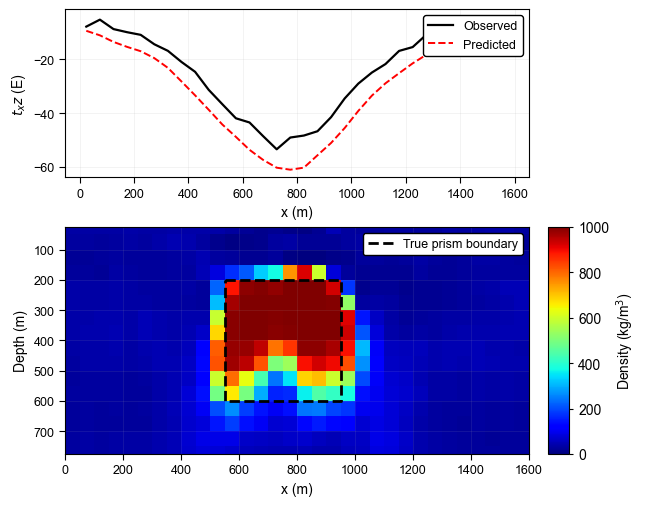

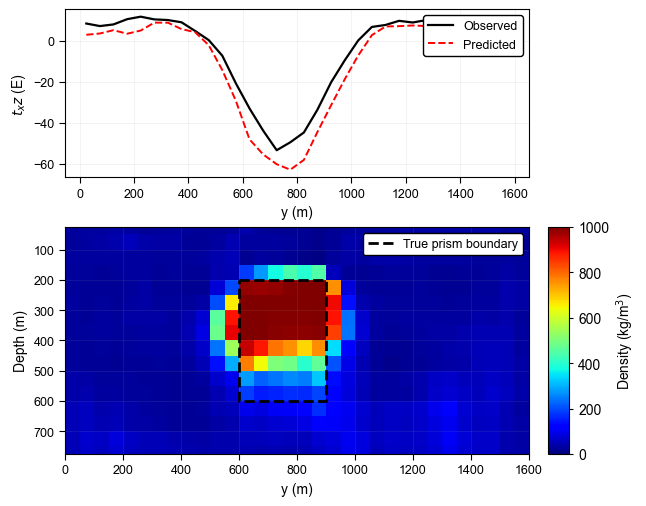

In [2]:
# =====================================================================
# 14–15. EW/NS tyy PROFILE + tyy DENSITY SECTION
# =====================================================================
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib as mpl

# =====================================================================
# PROFILE + DENSITY-SECTION FUNCTION
# =====================================================================
def plot_profile_density_section(direction="EW", coordinate=750,
                                 filename="Profile_Density_Section.png"):

    # --- True prism bounds ---
    px_lo, px_hi = 550., 950.
    py_lo, py_hi = 600., 900.
    pz_lo, pz_hi = 200., 600.
        
    # --- Model cell centres ---
    xc, yc, zc = [(a[:-1] + a[1:]) / 2 for a in (xe, ye, ze)]

    # --- Select profile and density section ---
    if direction.upper() == "EW":
        i = np.argmin(abs(Y[:, 0] - coordinate))
        profile, obs, pred = X[i], Zobs[i], Zpred[i]

        pd.DataFrame({
            "x (m)": profile,
            "Observed tyy (E)": obs,
            "Predicted tyy (E)": pred
        }).to_excel("XZ_tyy_Profile_y750.xlsx", index=False)

        j = np.argmin(abs(yc - coordinate))
        section = mp3[:, j, :]
        Xsec, Zsec = np.meshgrid(xc, zc)
        xlabel = "x (m)"

    elif direction.upper() == "NS":
        i = np.argmin(abs(X[0] - coordinate))
        profile, obs, pred = Y[:, i], Zobs[:, i], Zpred[:, i]

        pd.DataFrame({
            "y (m)": profile,
            "Observed tyy (E)": obs,
            "Predicted tyy (E)": pred
        }).to_excel("YZ_tyy_Profile_x750.xlsx", index=False)

        j = np.argmin(abs(xc - coordinate))
        section = mp3[:, :, j]
        Xsec, Zsec = np.meshgrid(yc, zc)
        xlabel = "y (m)"

    else:
        raise ValueError("direction must be 'EW' or 'NS'")

    # --- Figure layout ---
    fig = plt.figure(figsize=(6, 5))
    gs = fig.add_gridspec(
        2, 2, height_ratios=[1, 1.35],
        width_ratios=[1, .045], hspace=.25, wspace=.08
    )
    ax1 = fig.add_subplot(gs[0, 0])
    ax2 = fig.add_subplot(gs[1, 0])
    cax = fig.add_subplot(gs[1, 1])
    fig.patch.set_facecolor(BG)

    # --- (a) tyy profile ---
    ax1.plot(profile, obs, "k", lw=1.6, label="Observed")
    ax1.plot(profile, pred, "r--", lw=1.4, label="Predicted")
    _style(ax1, xlabel, r"$t_xz$ (E)")
    ax1.tick_params(axis="both", labelsize=9)
    ax1.grid(True, lw=.4, alpha=.25)
    ax1.legend(
        loc="upper right", frameon=True, framealpha=1,
        edgecolor="black", fontsize=9
    )

    # --- (b) tyy density section ---
    pcm = ax2.pcolormesh(
        Xsec, Zsec, section, cmap="jet",
        vmin=0, vmax=1000, shading="auto"
    )
    ax2.set_ylim(zc.max(), zc.min())
    _style(ax2, xlabel, "Depth (m)")
    ax2.tick_params(axis="both", labelsize=9)
    ax2.grid(True, lw=.4, alpha=.20)

    # --- True prism boundary ---
    boundary_x = (
        [px_lo, px_hi, px_hi, px_lo, px_lo]
        if direction.upper() == "EW"
        else [py_lo, py_hi, py_hi, py_lo, py_lo]
    )
    boundary_z = [pz_lo, pz_lo, pz_hi, pz_hi, pz_lo]

    ax2.plot(
        boundary_x, boundary_z,
        "k--", lw=2.0, zorder=10,
        label="True prism boundary"
    )
    ax2.legend(
        loc="upper right", fontsize=9,
        frameon=True, framealpha=1, edgecolor="black"
    )

    # --- Density colorbar ---
    cb = fig.colorbar(pcm, cax=cax)
    cb.set_label(r"Density (kg/m$^3$)", fontsize=10, color=TC)
    cb.ax.tick_params(
        labelsize=10, colors=TC,
        direction="out", width=.8, length=3
    )
    cb.outline.set_edgecolor(TC)
    cb.outline.set_linewidth(.8)

    # --- Save figure ---
    fig.subplots_adjust(
        left=.10, right=.94, top=.97, bottom=.08
    )
    fig.savefig(
        filename, dpi=600,
        bbox_inches="tight", facecolor=BG
    )
    plt.show()
    plt.close(fig)
# =====================================================================
# FIGURE 13 — EW/XZ AT y = 750 m
# =====================================================================
plot_profile_density_section(
    "EW", 750,
    "Fig14_EW_XZ_Profile_Density_Section_y750.png"
)
# =====================================================================
# FIGURE 14 — NS/YZ AT x = 750 m
# =====================================================================
plot_profile_density_section(
    "NS", 750,
    "Fig15_NS_YZ_Profile_Density_Section_x750.png"
)